# Biodiversity in Different National Parks

## Introduction

Data has been collected from select national parks, noting the unique species that are observed as well as the number of times they were spotted. Moreover, data has been collected on each species, specifying their species category, common name, scientific name, and their conservation status. This report will analyze the species diversity and recorded observation counts across these national parks as well, including searching for patterns and commonalities among endangered species, biodiversity, and observability.

## Data Preparation, Analysis, and Visualization


Questions:
1. How do recorded species counts and total observations differ between parks?
2. How do plants and animals compare in species counts and observations?
3. How are conservation statuses distributed across species categories?
4. How do mean observations per species differ by category and conservation status within each park?

Using these questions as a guideline, we will observe the data files and make necessary changes and merges in order to clean up the data.

In [59]:
#import everything and read csv files:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

species = pd.read_csv('species_info.csv')
#later on we make an edit to species. Here we make a copy to preserve the original.
species_original = species.copy()
observations = pd.read_csv('observations.csv')

In [3]:
#display top 5 rows of each table and give info of column heads
display(species.head())
display(observations.head())

species.info()
observations.info()

,category,scientific_name,common_names,conservation_status
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,NaN
1,Mammal,Bos bison,"American Bison, Bison",NaN
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",NaN
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",NaN
4,Mammal,Cervus elaphus,Wapiti Or Elk,NaN


,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5824 entries, 0 to 5823
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   category             5824 non-null   object
 1   scientific_name      5824 non-null   object
 2   common_names         5824 non-null   object
 3   conservation_status  191 non-null    object
dtypes: object(4)
memory usage: 182.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23296 entries, 0 to 23295
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   scientific_name  23296 non-null  object
 1   park_name        23296 non-null  object
 2   observations     23296 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 546.1+ KB


Species file: category (eg mammal, vascular plant), scientific_name, common_names, conservation status.

Observation file: scientific_name, park_name, observations (integer column).

All data types except observations are object types.

In [62]:
# number of rows and columns:
print('species rows x columns:' + str(species.shape))
print('observations rows x columns:' + str(observations.shape))

species rows x columns:(5824, 4)
observations rows x columns:(23296, 3)


In [5]:
print(f'National Parks Observed: {observations.park_name.unique()}')

National Parks Observed: ['Great Smoky Mountains National Park' 'Yosemite National Park'
 'Bryce National Park' 'Yellowstone National Park']


We will be looking across 4 different national parks: Great Smoky Mountains National Park, Yosemite National Park, Bryce National Park, and Yellowstone National Park.

In [63]:
print(f'Categories of species observed: {species.category.unique()}')
#we observe later on that there exist duplicates. Thus, we group by category, and see how many unique scientific names belong to each category.
species.groupby('category')['scientific_name'].nunique()

Categories of species observed: ['Mammal' 'Bird' 'Reptile' 'Amphibian' 'Fish' 'Vascular Plant'
 'Nonvascular Plant']


category
Amphibian              79
Bird                  488
Fish                  125
Mammal                176
Nonvascular Plant     333
Reptile                78
Vascular Plant       4262
Name: scientific_name, dtype: int64

We will be reviewing the following types of species: Mammals, Birds, Reptiles, Amphibians, Fish, Vascular Plants, and Nonvascular Plants. We may further generalize the first five into 'animals' and the last two into 'plants.'

In [7]:
#number of unique species observed all across the board
print(f'Total number of species observed in data: {observations.scientific_name.nunique()}')
#number of unique species observed in GSM NP
print(f'Total number of species observed in each park: {observations.groupby('park_name').scientific_name.nunique()}')


Total number of species observed in data: 5541
Total number of species observed in each park: park_name
Bryce National Park                    5541
Great Smoky Mountains National Park    5541
Yellowstone National Park              5541
Yosemite National Park                 5541
Name: scientific_name, dtype: int64


The dataset contains the same number of unique scientific names in each park.

In [64]:
print(f"Rows with zero observations: {observations.observations.eq(0).sum()}")

Rows with zero observations: 0


Since there are no rows with zero observations, each park has at least one recorded observation per species included in the dataset.

In [8]:
#total number of observations across all parks
print(f'Total number of observations: {observations.observations.sum()}')

#total number of observations per park
print(f'Total number of observations per each park: {observations.groupby('park_name').observations.sum()}')

Total number of observations: 3314739
Total number of observations per each park: park_name
Bryce National Park                     576025
Great Smoky Mountains National Park     431820
Yellowstone National Park              1443562
Yosemite National Park                  863332
Name: observations, dtype: int64


In [9]:
species["scientific_name"].duplicated().sum()
species[
    species["scientific_name"].duplicated(keep=False)
].sort_values("scientific_name")


,category,scientific_name,common_names,conservation_status
5553,Vascular Plant,Agrostis capillaris,"Colonial Bent, Colonial Bentgrass",NaN
2132,Vascular Plant,Agrostis capillaris,Rhode Island Bent,NaN
2134,Vascular Plant,Agrostis gigantea,Redtop,NaN
5554,Vascular Plant,Agrostis gigantea,"Black Bent, Redtop, Water Bentgrass",NaN
4178,Vascular Plant,Agrostis mertensii,"Arctic Bentgrass, Northern Bentgrass",NaN
...,...,...,...,...
5643,Vascular Plant,Vulpia myuros,"Foxtail Fescue, Rattail Fescue, Rat-Tail Fescu...",NaN
2331,Vascular Plant,Vulpia octoflora,Annual Fescue,NaN
4290,Vascular Plant,Vulpia octoflora,"Eight-Flower Six-Weeks Grass, Pullout Grass, S...",NaN
3347,Vascular Plant,Zizia aptera,"Heartleaf Alexanders, Heart-Leaf Alexanders, M...",NaN


Before we continue, let us compare the number of potential species we have to compare, whether they are plant or animal.

Total number of plants observed: 4595
Total number of animals observed: 946


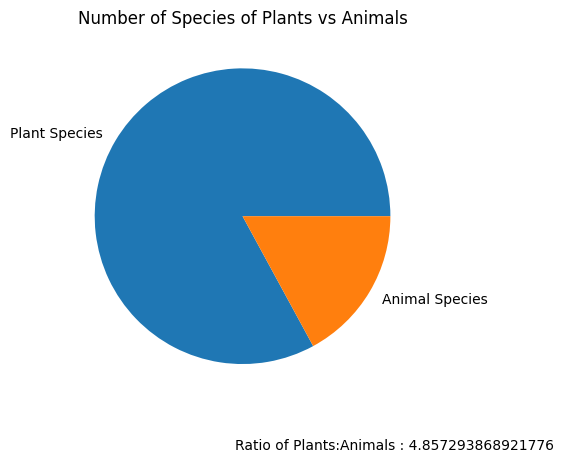

In [10]:
total_plant_species = species.loc[(species['category'] == 'Vascular Plant') | (species['category'] == 'Nonvascular Plant'), 'scientific_name'].nunique()
print(f'Total number of plants observed: {total_plant_species}')

total_animal_species = species.loc[(species['category'] != 'Vascular Plant') & (species['category'] != 'Nonvascular Plant'), 'scientific_name'].nunique()
print(f'Total number of animals observed: {total_animal_species}')

plt.pie([total_plant_species, total_animal_species], labels=['Plant Species', 'Animal Species'])
plt.title('Number of Species of Plants vs Animals')
plt.figtext(0.5, 0.01, f'Ratio of Plants:Animals : {total_plant_species/total_animal_species}')
plt.show()

Note that there are some duplicates. Moving forward, let us merge the species category into observations while dropping these duplicates.

In [11]:
merged_categories = pd.merge(observations, species[['scientific_name', 'category']].drop_duplicates(), on='scientific_name')

print(merged_categories.head())
#check to make sure that merged_categories has the same shape as _ categories
print(merged_categories.shape[0] == observations.shape[0])

            scientific_name                            park_name  \
0        Vicia benghalensis  Great Smoky Mountains National Park   
1            Neovison vison  Great Smoky Mountains National Park   
2         Prunus subcordata               Yosemite National Park   
3      Abutilon theophrasti                  Bryce National Park   
4  Githopsis specularioides  Great Smoky Mountains National Park   

   observations        category  
0            68  Vascular Plant  
1            77          Mammal  
2           138  Vascular Plant  
3            84  Vascular Plant  
4            85  Vascular Plant  
True


Total number of plants observed: 2745743
Total number of animals observed: 568996


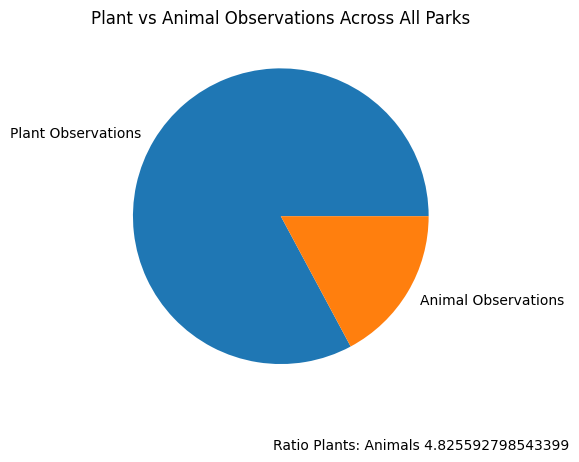

In [12]:
#Division of total plants vs animals observed:
total_plant_obs = merged_categories.loc[(merged_categories['category'] == 'Vascular Plant') | (merged_categories['category'] == 'Nonvascular Plant'), 'observations'].sum()
print(f'Total number of plants observed: {total_plant_obs}')

total_animal_obs = merged_categories.loc[(merged_categories['category'] != 'Vascular Plant') & (merged_categories['category'] != 'Nonvascular Plant'), 'observations'].sum()
print(f'Total number of animals observed: {total_animal_obs}')

plt.pie([total_plant_obs, total_animal_obs], labels=['Plant Observations', 'Animal Observations'])
plt.title('Plant vs Animal Observations Across All Parks')
plt.figtext(0.5, 0.01, f'Ratio Plants: Animals {total_plant_obs/total_animal_obs}')
plt.show()


What is interesting here is that the ratio of the observations of plants vs animals versus the ratio of the number of plant species vs animal species is almost 1:1. 

Total Plant Observations:Total Animal Observations ~ Unique Plant Species:Unique Animal Species
Total Plant Observations:Unique Plant Species ~ Total Animal Observations:Unique Animal Species

That is, we are observing plants at a rate proportional to our animal observations.

Total number of plants observed in Great Smoky Mountains National Park: 358476
Total number of animals observed: 73344
Total number of plants observed in Yosemite National Park: 715244
Total number of animals observed: 148088
Total number of plants observed in Bryce National Park: 476075
Total number of animals observed: 99950
Total number of plants observed in Yellowstone National Park: 1195948
Total number of animals observed: 247614


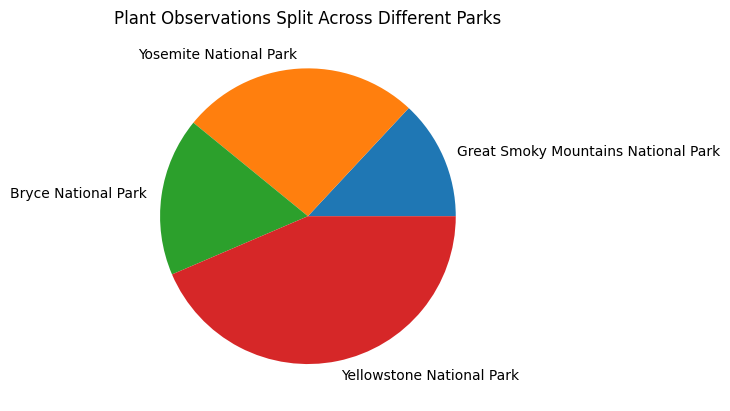

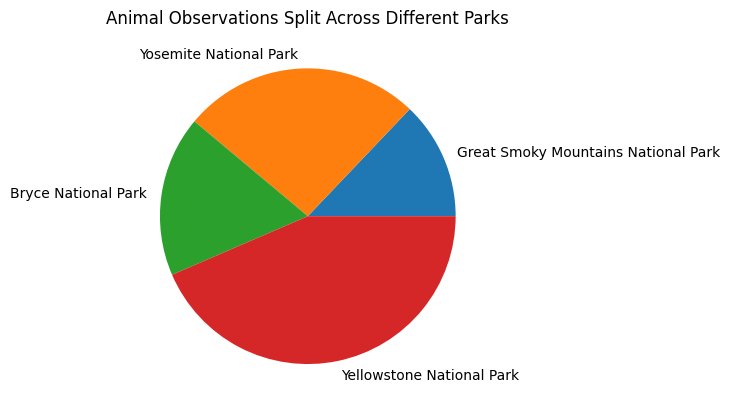

In [23]:
#Division of plants vs animals observed in each park
plant_obs_in_parks = []
animal_obs_in_parks = []
for park in merged_categories['park_name'].unique():
    total_plant_obs = merged_categories.loc[(merged_categories['park_name'] == park) & ((merged_categories['category'] == 'Vascular Plant') | (merged_categories['category'] == 'Nonvascular Plant')), 'observations'].sum()
    print(f'Total number of plants observed in {park}: {total_plant_obs}')
    plant_obs_in_parks.append(total_plant_obs)
    
    total_animal_obs = merged_categories.loc[(merged_categories['park_name'] == park) & ((merged_categories['category'] != 'Vascular Plant') & (merged_categories['category'] != 'Nonvascular Plant')), 'observations'].sum()
    print(f'Total number of animals observed: {total_animal_obs}')
    animal_obs_in_parks.append(total_animal_obs)

plt.pie(plant_obs_in_parks, labels=merged_categories['park_name'].unique())
plt.title('Plant Observations Split Across Different Parks')
plt.show()

plt.pie(animal_obs_in_parks, labels=merged_categories['park_name'].unique())
plt.title('Animal Observations Split Across Different Parks')
plt.show()

In the above pie charts, we can see that Yellowstone National Park observes the most, whether plant or animal, in about the same proportion. Then Yosemite, Bryce, and the Great Smoky Mountains. Moving forward when encountering endangered species observations by park, their proportion relative to the amount of observations that specific park makes should be kept in mind. For example, if an endangered plant is seen more times in Yosemite than it is in Great Smoky Mountains, that does not necessarily imply that it is doing 'better' in Yosemite than in Great Smoky Mountains.

Now, let us compare plant to animal observations in each park.

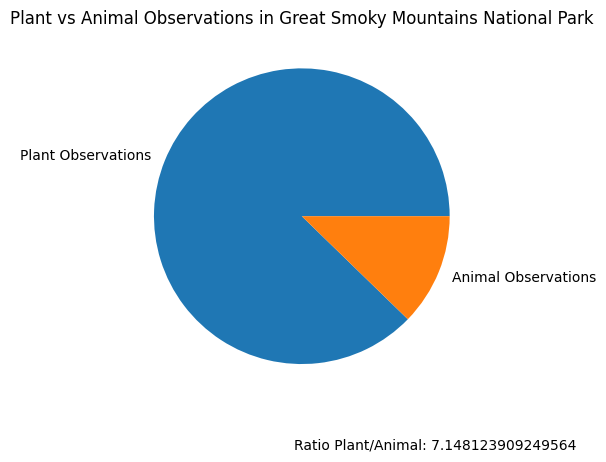

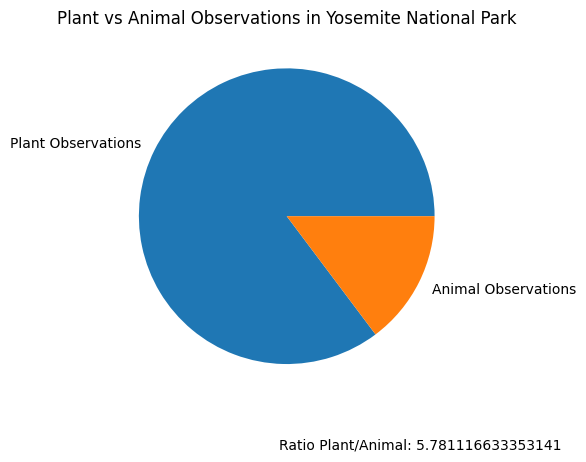

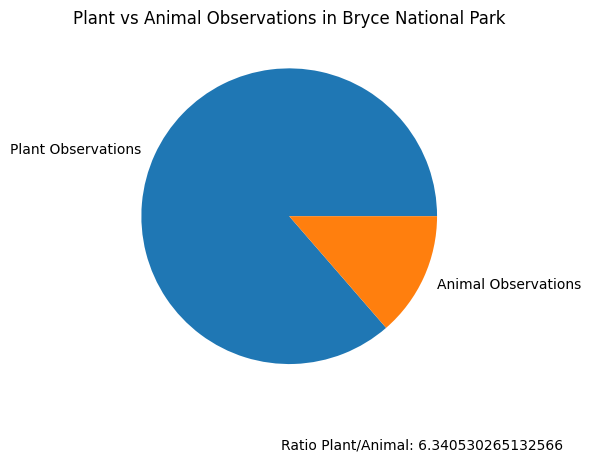

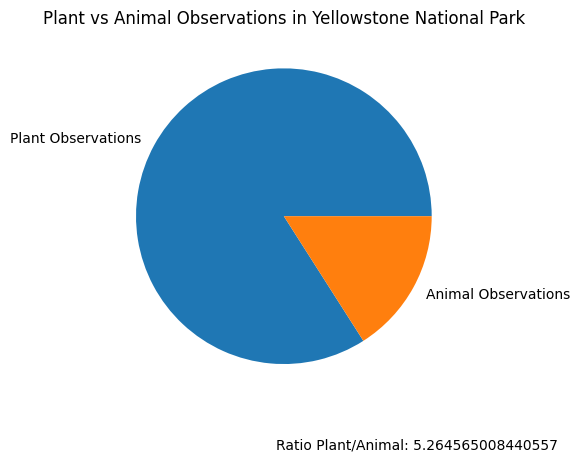

In [14]:
i = 0
for park in merged_categories['park_name'].unique():
    plt.pie([plant_obs_in_parks[i], animal_obs_in_parks[i]], labels=['Plant Observations', 'Animal Observations'])
    plt.title(f'Plant vs Animal Observations in {park}')
    plt.figtext(0.5, 0.01, f'Ratio Plant/Animal: {plant_obs_in_parks[i]/animal_obs_in_parks[i]}')
    plt.show()
    i+=1

In the above pie charts, we can see that there is a fairly similar ratio across the board between plants and animals observed in each park, ranging from about 5 to 7. It will be interesting to note whether this has an impact on the number observations of endangered species relative to their category type. That is, will an endangered plant be seen more than an endangered animal? 

However, we may also recall from above that these observation ratios are similar, though slightly higher than the original 4.8, to the ratio between species and the ratio between the observations of the species (by type).

In [15]:
#conservation status types (unique)
print(f'Conservation status types: {species.conservation_status.unique()}')

Conservation status types: [nan 'Species of Concern' 'Endangered' 'Threatened' 'In Recovery']


Here, we see five levels of conservation status. Here, 'nan' means 'No Intervention'. Endangered means that the species is at risk of extinction. Threatened means that the species is at risk of being endangered in the foreseeable future. Species of concern are those whose population status is worrisome and declining, but not yet formally protected under law. A species that is 'In Recovery' is one that formerly endangered, but is undergoing a conservation plan and has seen a reduction in threat.

In [16]:
#replace na with 'No Intervention'
species.fillna('No Intervention', inplace = True)
species.groupby('conservation_status').size()

conservation_status
Endangered              16
In Recovery              4
No Intervention       5633
Species of Concern     161
Threatened              10
dtype: int64

According to Codecademy's data "solution," species with missing values in their conservation status may be interpreted as "No Intervention." Now, we will explore the division of species categories in each conservation type. For example, we may be able to compare whether there is a higher proportion of animals than vascular plants that are endangered.

In [17]:
status_counts = species.groupby("scientific_name")[
    "conservation_status"
].nunique(dropna=False)

multiple_statuses = status_counts[status_counts > 1]

species.loc[
    species["scientific_name"].isin(multiple_statuses.index)
].sort_values("scientific_name")

,category,scientific_name,common_names,conservation_status
8,Mammal,Canis lupus,Gray Wolf,Endangered
3020,Mammal,Canis lupus,"Gray Wolf, Wolf",In Recovery
4448,Mammal,Canis lupus,"Gray Wolf, Wolf",Endangered
560,Fish,Oncorhynchus mykiss,Rainbow Trout,No Intervention
3283,Fish,Oncorhynchus mykiss,Rainbow Trout,Threatened


In [18]:
print(multiple_statuses.index.tolist())

['Canis lupus', 'Oncorhynchus mykiss']


Above, we see two species with conflicting conservation statuses. For the following analysis, we will assign each to the more protective of its recorded status to avoid a) understating conservation concerns and b) duplicating observation counts during data merging. 

Note: These reassignments are an analytical convention that should not be confused with a verified correction of the original data. The original entries remain preserved and the conflicting statuses of these two species remain a limiting factor in the analysis.

In [19]:
species.loc[species['scientific_name'] == 'Canis lupus', 'conservation_status'] = 'Endangered'
species.loc[species['scientific_name'] == 'Oncorhynchus mykiss', 'conservation_status'] = 'Threatened'

#merge conservation status into merged_observations
merged = pd.merge(merged_categories, species[['scientific_name', 'conservation_status']].drop_duplicates(), on='scientific_name')
print(merged.head())
#check to make sure that merged_categories has the same shape as merged
print(merged_categories.shape[0] == merged.shape[0])


            scientific_name                            park_name  \
0        Vicia benghalensis  Great Smoky Mountains National Park   
1            Neovison vison  Great Smoky Mountains National Park   
2         Prunus subcordata               Yosemite National Park   
3      Abutilon theophrasti                  Bryce National Park   
4  Githopsis specularioides  Great Smoky Mountains National Park   

   observations        category conservation_status  
0            68  Vascular Plant     No Intervention  
1            77          Mammal     No Intervention  
2           138  Vascular Plant     No Intervention  
3            84  Vascular Plant     No Intervention  
4            85  Vascular Plant     No Intervention  
True


Question: How are different conservation statuses divided by species category?

conservation_status  Endangered  In Recovery  No Intervention  \
category                                                        
Amphibian                   1.0          NaN             72.0   
Bird                        4.0          3.0            413.0   
Fish                        3.0          NaN            114.0   
Mammal                      6.0          NaN            146.0   
Nonvascular Plant           NaN          NaN            328.0   
Reptile                     NaN          NaN             73.0   
Vascular Plant              1.0          NaN           4216.0   

conservation_status  Species of Concern  Threatened  
category                                             
Amphibian                           4.0         2.0  
Bird                               68.0         NaN  
Fish                                4.0         4.0  
Mammal                             22.0         2.0  
Nonvascular Plant                   5.0         NaN  
Reptile                             

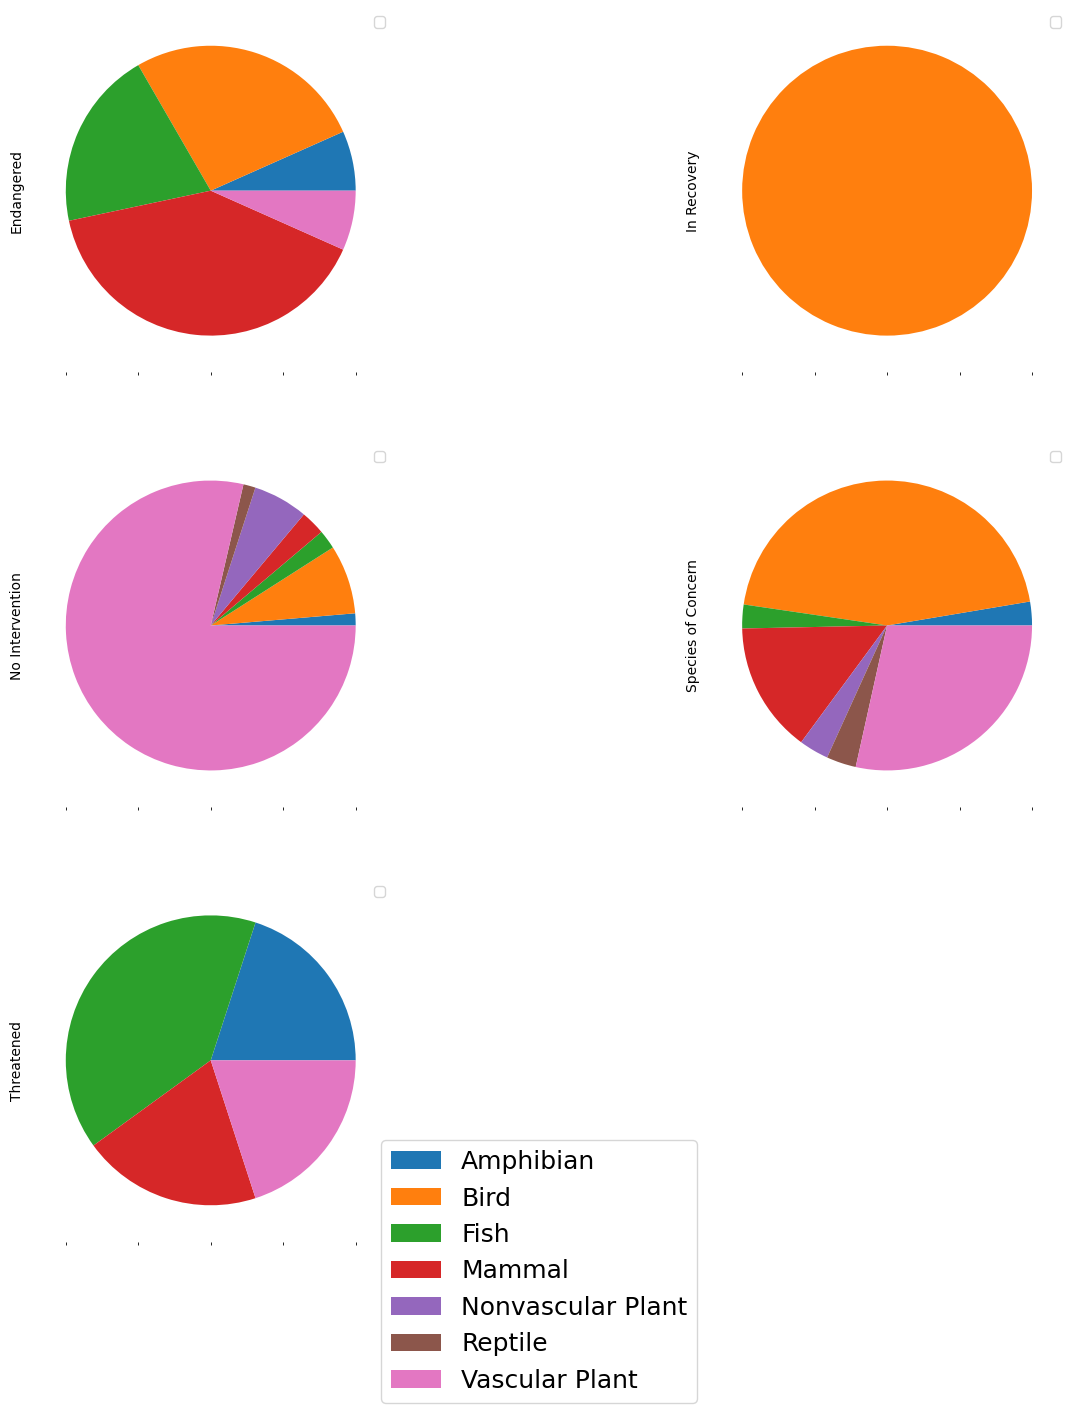

In [20]:

status_categories_division = species.drop_duplicates(subset='scientific_name').groupby(['category', 'conservation_status'])['scientific_name'].count().unstack()
print(status_categories_division)

axes = status_categories_division.plot(kind = 'pie', subplots=True, layout=(-1, 2), figsize=(16, 16), labels=None)
plt.gcf().legend(status_categories_division.index, loc="lower center", fontsize=18)
plt.show()

        

Next, we will observe the converse. Let us divide each species category into their conservation statuses. That is, we may answer the question, "What proportion of bird species are threatened?" rather than "What proportion of threatened species are birds?"

conservation_status  Endangered  In Recovery  No Intervention  \
category                                                        
Amphibian                   1.0          0.0             72.0   
Bird                        4.0          3.0            413.0   
Fish                        3.0          0.0            114.0   
Mammal                      6.0          0.0            146.0   
Nonvascular Plant           0.0          0.0            328.0   
Reptile                     0.0          0.0             73.0   
Vascular Plant              1.0          0.0           4216.0   

conservation_status  Species of Concern  Threatened  
category                                             
Amphibian                           4.0         2.0  
Bird                               68.0         0.0  
Fish                                4.0         4.0  
Mammal                             22.0         2.0  
Nonvascular Plant                   5.0         0.0  
Reptile                             

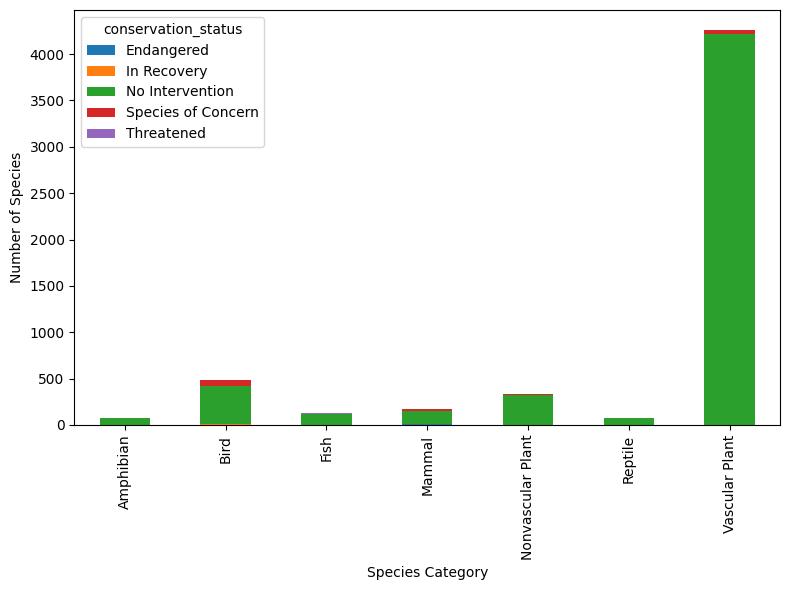

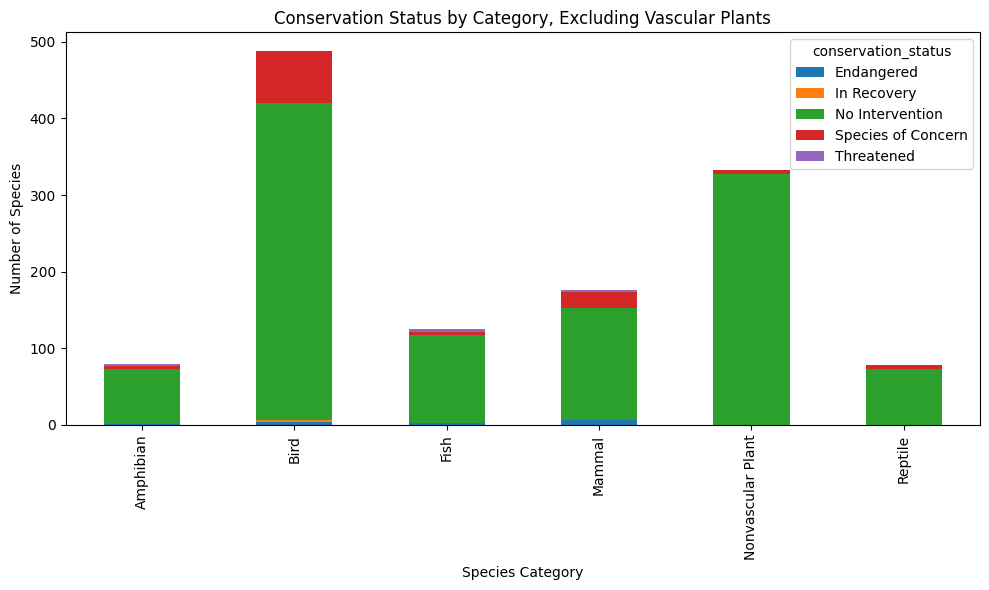

In [29]:
cat_by_stat_div = species.drop_duplicates(subset='scientific_name').groupby(['category', 'conservation_status'])['scientific_name'].count().unstack().fillna(0)
print(cat_by_stat_div)

ax = cat_by_stat_div.plot(kind = 'bar', figsize=(8,6), 
                               stacked=True)
ax.set_xlabel("Species Category")
ax.set_ylabel("Number of Species")
plt.tight_layout()
plt.show()

ax = cat_by_stat_div.drop(index="Vascular Plant").plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_xlabel("Species Category")
ax.set_ylabel("Number of Species")
ax.set_title("Conservation Status by Category, Excluding Vascular Plants")
plt.tight_layout()
plt.show()


The above bar charts show that the vast majority of species belonging to each category are listed as having no intervention. Mammals have the highest proportion of species not having "No Intervention" labels. However, birds have the highest proportion classified as "Species of Concern" with mammals following.

Now, let us observe average number of observations per species. We will use this to compare average number of observations by type of species as well as by their conservation statuses. That is, we may answer "do mammals have lower mean recorded observations than plants?"

                             park_name  ave_num_observations  \
0                  Bryce National Park            103.956867   
1  Great Smoky Mountains National Park             77.931781   
2            Yellowstone National Park            260.523732   
3               Yosemite National Park            155.807977   

   ave_obs_Amphibian  ave_obs_Bird  ave_obs_Fish  ave_obs_Mammal  \
0          93.417722    105.834016        99.384      116.761364   
1          72.240506     77.311475        73.648       85.295455   
2         246.075949    260.760246       244.592      288.607955   
3         144.860759    156.161885       148.920      172.380682   

   ave_obs_Nonvascular Plant  ave_obs_Reptile  ave_obs_Vascular Plant  
0                  99.075075       101.923077              103.961286  
1                  74.645646        72.961538               78.277569  
2                 249.312312       250.692308              261.127874  
3                 149.498498       147.217949     

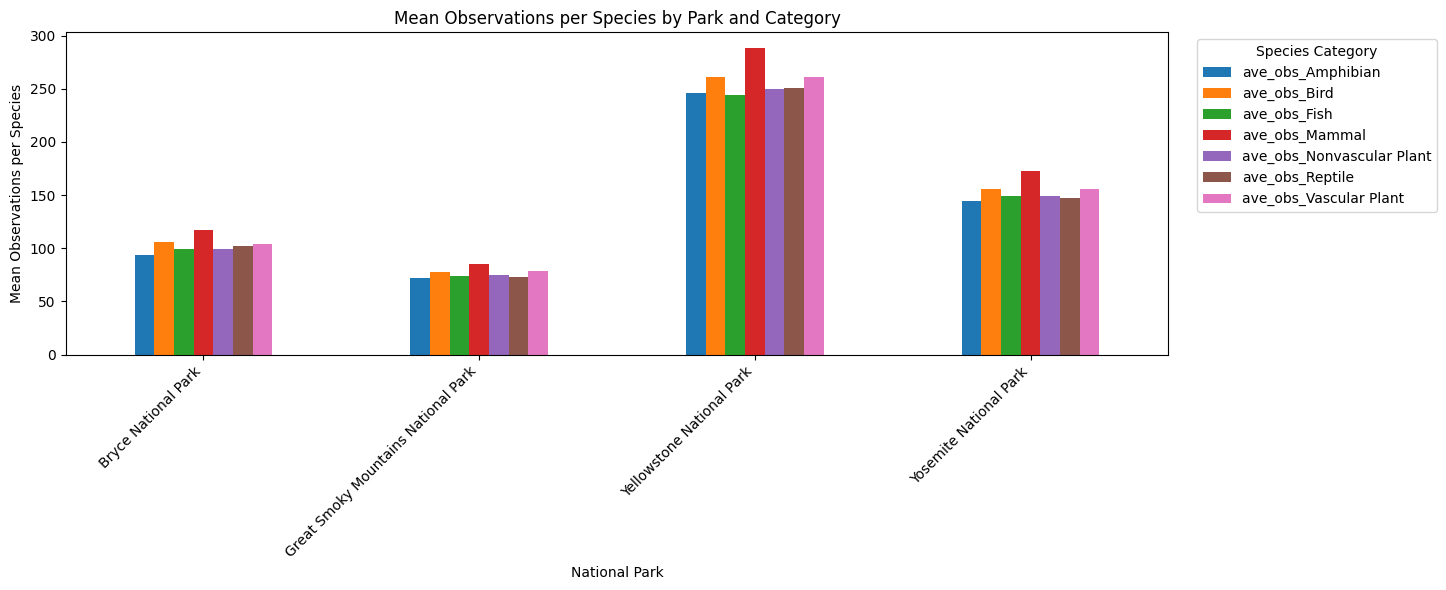

In [65]:
#Here we make sure that a species is not counted twice as having separate observations. For example
#if Yosemite says they counted 20 wolf observations and 20 more wolf observations, we say here that it is 40
species_totals= merged.groupby(["park_name", "scientific_name", "category", "conservation_status"])["observations"].sum().reset_index()
#Find the average of number of observations across each park
ave_num_obs = species_totals.groupby('park_name').observations.mean().rename('ave_num_observations')
ave_by_cat = species_totals.groupby(['park_name', 'category']).observations.mean().unstack()
ave_by_cat.columns = ["ave_obs_"+category for category in ave_by_cat.columns]
park_aves = ave_num_obs.to_frame().join(ave_by_cat).reset_index()

print(park_aves)

ax = park_aves.set_index("park_name").drop(
    columns="ave_num_observations"
).plot(kind="bar", figsize=(12, 6))

ax.set_title("Mean Observations per Species by Park and Category")
ax.set_xlabel("National Park")
ax.set_ylabel("Mean Observations per Species")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Species Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Interestingly, they are similar in scale according to each park, with mammals having a consistently slight lead in each park. This suggests that plants may dominate total recorded observations simply because there are significantly more plant species than animal species.

Now, let us observe mean observations per park by conservation status.

                             park_name  ave_num_observations  \
0                  Bryce National Park            103.956867   
1  Great Smoky Mountains National Park             77.931781   
2            Yellowstone National Park            260.523732   
3               Yosemite National Park            155.807977   

   ave_obs_Endangered  ave_obs_In Recovery  ave_obs_No Intervention  \
0           32.600000            86.000000               104.394256   
1           22.266667            63.000000                78.430250   
2           81.866667           186.333333               261.940880   
3           49.800000           128.666667               156.620477   

   ave_obs_Species of Concern  ave_obs_Threatened  
0                   98.841060                59.1  
1                   68.304636                44.0  
2                  237.013245               145.9  
3                  142.721854                84.9  


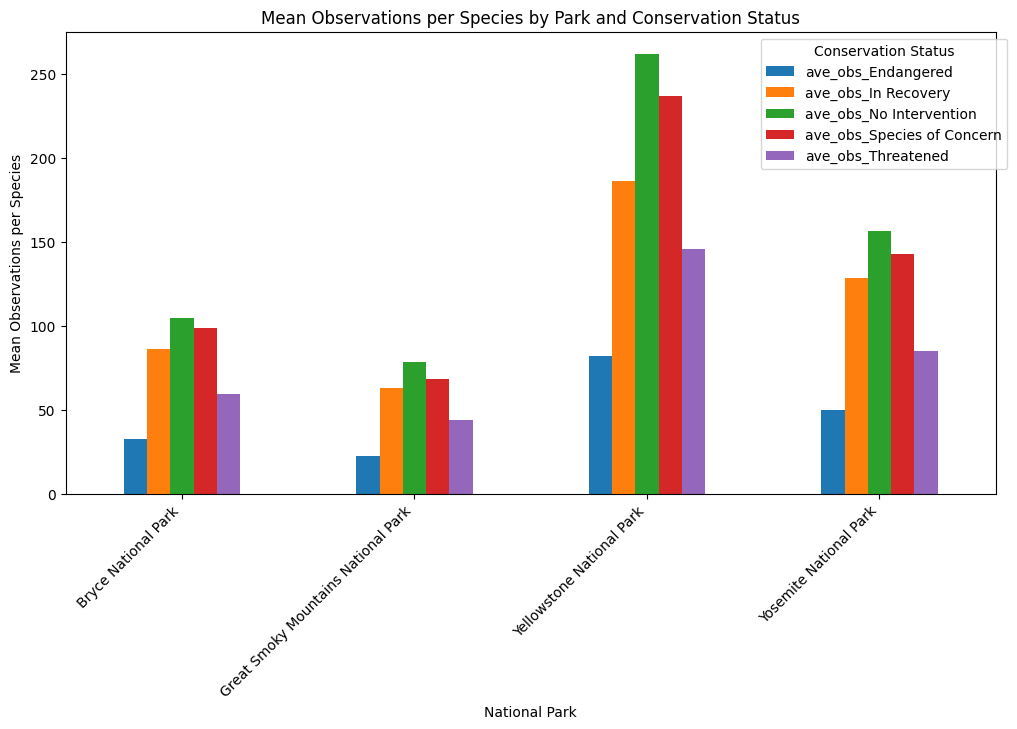

In [66]:
ave_num_obs = species_totals.groupby('park_name').observations.mean().rename('ave_num_observations')
ave_by_cs = species_totals.groupby(['park_name', 'conservation_status']).observations.mean().unstack()
ave_by_cs.columns = ["ave_obs_"+conservation_status for conservation_status in ave_by_cs.columns]
park_aves_cs = ave_num_obs.to_frame().join(ave_by_cs).reset_index()

print(park_aves_cs)

ax = park_aves_cs.set_index("park_name").drop(
    columns="ave_num_observations"
).plot(kind="bar", figsize=(12, 6))

ax.set_title("Mean Observations per Species by Park and Conservation Status")
ax.set_xlabel("National Park")
ax.set_ylabel("Mean Observations per Species")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Conservation Status", bbox_to_anchor=(1.02, 1))


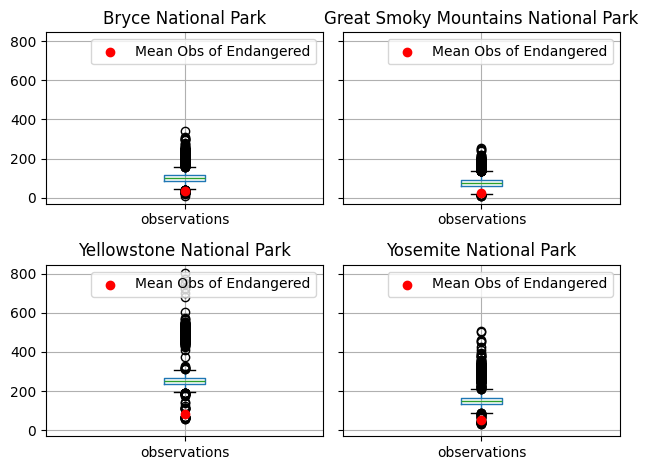

,count,mean,median,std
park_name,,,,
Bryce National Park,5541,103.96,100.0,30.72
Great Smoky Mountains National Park,5541,77.93,75.0,26.70
Yellowstone National Park,5541,260.52,250.0,60.84
Yosemite National Park,5541,155.81,150.0,39.97


In [71]:
axes = species_totals.groupby('park_name').boxplot(column = 'observations')
for park, ax in axes.items():
    ax.scatter(
        1,
        ave_by_cs.loc[park, "ave_obs_Endangered"],
        color="red",
        label='Mean Obs of Endangered',
        zorder=3
    )
    ax.legend()
plt.tight_layout()
plt.show()

summary_stats = species_totals.groupby("park_name")["observations"].agg(["count", "mean", "median", "std"])

display(summary_stats.round(2))

As we can see above, endangered species have fewer recorded observations per species on average.

## Findings and Conclusion

The analysis examined various species and their recorded observations across four National Parks: Bryce, Great Smoky Mountains, Yellowstone, and Yosemite. The datasets contained 5,541 unique scientific names, and each species was recorded to have at least one observation in each park. Thus, the provided datasets allowed for a common set of species for comparisons. However, this did not necessarily suggest equivalent observation efforts across each park. That is, we cannot infer differences in survey efforts put forth from each park based on observation totals alone.

Yellowstone had the highest total observation count, followed by Yosemite, Bryce, and finally, the Great Smoky Mountains. This ordering held for both plant and animal observations separately. Plants accounted for the majority of observations; however, the vast majority of species recorded were plants. There were 4,595 species of plants compared to only 946 animal species. Moreover, a higher total number of plant observations does not imply that an individual plant species was observed more frequently.

Most species were assigned with missing values (NaN) with respect to conservation status. According to Codecademy, this was to be interpreted as "No Intervention." Although mammals had the highest proportion of species that were not classified as "No Intervention," birds had the highest proportion of species labeled "Species of Concern." 

Within each park, endangered species had fewer recorded observations per species on average compared to the overall average of species observations. The box plots placed these endangered species means in the context of the distribution of observations across all species according to each park. Differences between the overall means and medians also highlighted the influence of outlier species that had unusually high observation counts.

A few limitations may affect these findings. First, observation counts do not directly measure population sizes, and differences may reflect survey effort or how readily species can be detected. Repeated records for the same species within a park were summed under the assumption that their observation counts were additive. Another limitation was the conflicting conservation statuses for the gray wolf and rainbow trout, which were resolved by using the more protective recorded status.

Overall, the datasets show differences in recorded observations between parks and conservation status groups. Although these patterns describe the present data, they do not confirm why a species was observed more or less frequently or which park achieved better conservation outcomes.

